# 03 – Baselines

Simple benchmarks that every model must beat (CLAUDE.md section 6, lectures 1 and 5):

| Model | Forecast of the 24 prices of day D |
|---|---|
| `naive_d1` | prices of D−1 at the same hours |
| `naive_d7` | prices of D−7 at the same hours |
| `naive_ref` | D−7 if D is a Monday, Saturday or Sunday, D−1 otherwise |

`naive_ref` is the **reference naive** of the `epftoolbox` convention (Lago et al., 2021): D−1 carries the most recent price level, but it is a poor guide when D and D−1 do not share the same weekly regime (Saturday after a working Friday, Sunday after Saturday, Monday after a weekend). Its MAE is the denominator of the **rMAE** of every model.

Each model is run with the common rolling loop (`src.evaluation.run_rolling`) on the main test period and on the control period. The naives only read past prices from `history` (up to D−1 23:00) and the day of week of D. They return no quantiles (empty `q10` … `q90` columns). Forecasts are cached in `results/` and `results/control/`.

The additive Holt-Winters model is added in a second section of this notebook.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg
from src.baselines import NaiveD1, NaiveD7, NaiveReference
from src.data import load_dataset, split_for_day
from src.evaluation import mae, rmse, run_rolling

df = load_dataset()
CONTROL_DAYS = pd.date_range(cfg.CONTROL_START, cfg.CONTROL_END, freq="D")

print(f"Dataset: {df.index[0]} → {df.index[-1]}")
print(f"Main test: {len(cfg.TEST_DAYS)} days, control: {len(CONTROL_DAYS)} days ({CONTROL_DAYS[0].date()} → {CONTROL_DAYS[-1].date()})")

Dataset: 2023-01-01 00:00:00 → 2026-11-08 23:00:00
Main test: 183 days, control: 24 days (2026-10-16 → 2026-11-08)


## 1. Naive forecasts

### 1.1 Check on one week

First week of the main test (Wednesday 1 April → Tuesday 7 April 2026): the three naives against the actual prices. `naive_ref` follows `naive_d7` on Saturday, Sunday and Monday and `naive_d1` on the other days.

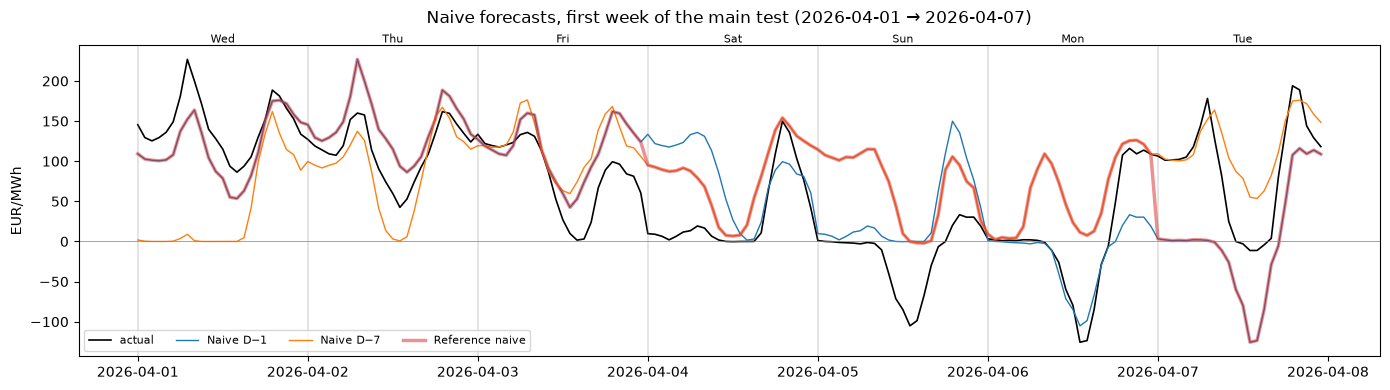

In [ ]:
naives = {"naive_d1": NaiveD1(), "naive_d7": NaiveD7(), "naive_ref": NaiveReference()}
labels = {"naive_d1": "Naive D−1", "naive_d7": "Naive D−7", "naive_ref": "Reference naive"}
colors = {"naive_d1": "C0", "naive_d7": "C1", "naive_ref": "C3"}

week = cfg.TEST_DAYS[:7]
fig, ax = plt.subplots(figsize=(14, 4))
actual = df.loc[week[0] : week[-1] + pd.Timedelta(hours=23), cfg.TARGET]
ax.plot(actual.index, actual, color="k", lw=1.2, label="actual")
for name, model in naives.items():
    forecasts = []
    for day in week:
        history, future_cov = split_for_day(df, day)
        y_pred, _ = model.predict(history, future_cov)
        forecasts.append(pd.Series(y_pred, index=future_cov.index))
    forecast = pd.concat(forecasts)
    ax.plot(forecast.index, forecast, color=colors[name], lw=2.5 if name == "naive_ref" else 1,
            alpha=0.5 if name == "naive_ref" else 1, label=labels[name])
for day in week:
    ax.axvline(day, color="grey", lw=0.3)
    ax.text(day + pd.Timedelta(hours=12), 1.0, day.strftime("%a"), transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("EUR/MWh")
ax.set_title(f"Naive forecasts, first week of the main test ({week[0].date()} → {week[-1].date()})", pad=16)
ax.legend(fontsize=8, ncol=4, loc="lower left")
fig.tight_layout()
plt.show()

### 1.2 Rolling evaluation

One forecast per day D, moving forward one day at a time. Each call only receives `split_for_day(df, D)`.

In [ ]:
res = {name: run_rolling(model, name, df, cfg.TEST_DAYS) for name, model in naives.items()}

naive_d1: loaded from results/naive_d1.parquet
naive_d7: loaded from results/naive_d7.parquet
naive_ref: loaded from results/naive_ref.parquet


In [ ]:
res_control = {
    name: run_rolling(model, name, df, CONTROL_DAYS, results_dir=cfg.RESULTS_DIR / "control")
    for name, model in naives.items()
}

naive_d1: loaded from results/control/naive_d1.parquet
naive_d7: loaded from results/control/naive_d7.parquet
naive_ref: loaded from results/control/naive_ref.parquet


### 1.3 Results

MAE and RMSE in EUR/MWh, and rMAE (MAE / MAE of `naive_ref` on the same days). The naives have no quantiles, so no pinball loss. Diebold-Mariano tests and the comparison with the other models are in `06_results.ipynb`.

In [ ]:
def summary(results: dict) -> pd.DataFrame:
    ref_mae = mae(results["naive_ref"]["y_true"], results["naive_ref"]["y_pred"])
    return pd.DataFrame({
        name: {
            "MAE": mae(r["y_true"], r["y_pred"]),
            "rMAE": mae(r["y_true"], r["y_pred"]) / ref_mae,
            "RMSE": rmse(r["y_true"], r["y_pred"]),
            "days": r["target_date"].nunique(),
        }
        for name, r in results.items()
    }).T.astype({"days": int})

table = pd.concat({"main test": summary(res), "control": summary(res_control)})
table.round(3)

MAE   rMAE     RMSE  days
main test naive_d1   33.040  0.943   53.696   183
          naive_d7   41.695  1.190   65.075   183
          naive_ref  35.049  1.000   56.978   183
control   naive_d1   39.491  0.539   56.869    24
          naive_d7   89.309  1.219  115.193    24
          naive_ref  73.293  1.000  102.684    24

In [ ]:
ref_main = table.loc[("main test", "naive_ref"), "MAE"]
ref_control = table.loc[("control", "naive_ref"), "MAE"]
print(f"Reference naive MAE (rMAE denominator): main test {ref_main:.2f} EUR/MWh, control {ref_control:.2f} EUR/MWh")

Reference naive MAE (rMAE denominator): main test 35.05 EUR/MWh, control 73.29 EUR/MWh


**Reference naive MAE: 35.05 EUR/MWh on the main test, 73.29 EUR/MWh on the control period.** These are the rMAE denominators of every model.

- On the main test, `naive_d1` (33.0) is slightly better than the reference naive (35.0), and `naive_d7` is the worst (41.7). The reference convention is kept as the protocol fixes it: rMAE < 1 means "better than the standard EPF naive", not "better than the best naive".
- The reference forecasts are identical to `epftoolbox.evaluation.naive_forecast(prices, m=None)` on all 4,392 + 576 hours (checked once, 2026-11-19, in the throwaway environment used for the Diebold-Mariano check).
- The control period is short (24 days, 11 of them forecast with D−7) and turbulent at the end of October: on the weekends of 24–25 October and 31 October – 1 November, D−7 is off by 140 to 240 EUR/MWh on average over the day. The reference MAE more than doubles while `naive_d1` only goes from 33 to 39. The rMAE level on the control period is therefore not comparable with the main test; for the contamination test, compare models with each other on the same period (e.g. the ranking, or the ratio of a foundation model's MAE to SARIMAX's).

### 1.4 Error by day of week and by hour

The reference naive takes, for each day of week, the lag that is expected to work best. The table below checks it on the main test: MAE of D−1 and D−7 by day of week of D.

In [ ]:
def mae_by(results: dict, key) -> pd.DataFrame:
    return pd.DataFrame({
        name: r.assign(err=(r["y_true"] - r["y_pred"]).abs()).groupby(key(r))["err"].mean()
        for name, r in results.items()
    })

by_dow = mae_by(res, lambda r: r["target_date"].dt.day_of_week)
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_dow["days"] = res["naive_ref"].groupby(res["naive_ref"]["target_date"].dt.day_of_week)["target_date"].nunique().to_numpy()
by_dow.round(2)

,naive_d1,naive_d7,naive_ref,days
Mon,50.59,50.71,50.71,26
Tue,33.90,39.60,33.90,26
Wed,22.58,36.87,22.58,27
Thu,29.01,38.17,29.01,26
Fri,26.72,43.80,26.72,26
Sat,44.12,40.38,40.38,26
Sun,24.77,42.51,42.51,26


On the main test (April–September), D−7 only helps on Saturday (40.4 vs 44.1 EUR/MWh); on Monday both lags are equal, and on Sunday D−1 (the Saturday) is much better than D−7 (24.8 vs 42.5): in spring and summer, Saturday and Sunday share the same low-demand, high-solar regime. Monday is the hardest day for both lags.

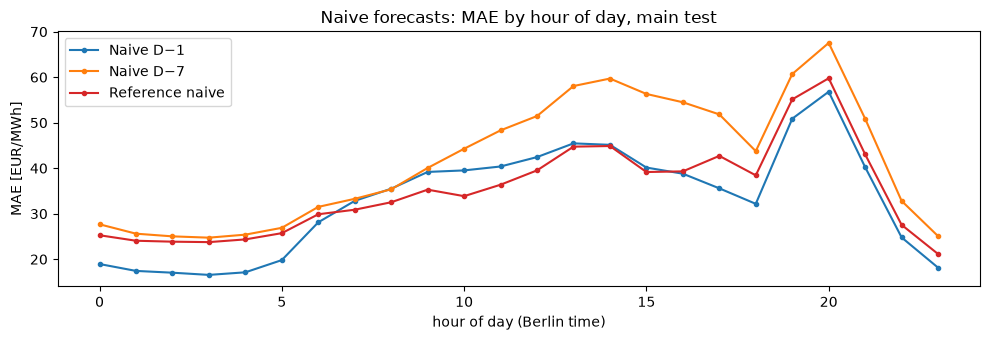

In [ ]:
by_hour = mae_by(res, lambda r: r["hour"])
ax = by_hour.rename(columns=labels).plot(figsize=(10, 3.5), marker="o", ms=3, color=[colors[c] for c in by_hour])
ax.set_xlabel("hour of day (Berlin time)")
ax.set_ylabel("MAE [EUR/MWh]")
ax.set_title("Naive forecasts: MAE by hour of day, main test")
plt.tight_layout()
plt.show()